In [1]:
import numpy as np
import pandas as pd
import torch

from sklearn.model_selection import StratifiedKFold
from torch.utils.data import DataLoader, TensorDataset

train = pd.read_json("data/train.json")

band1 = np.stack(train["band_1"]).reshape(-1, 75, 75)
band2 = np.stack(train["band_2"]).reshape(-1, 75, 75)

X = np.stack([band1, band2], axis=1).astype(np.float32)
y = train["is_iceberg"].to_numpy(dtype=np.int64)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("X:", X.shape)
print("y:", y.shape)
print("Device:", device)

X: (1604, 2, 75, 75)
y: (1604,)
Device: cuda


In [2]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X, y), start=1
):
    print(
        f"Fold {fold}: "
        f"Train = {len(train_idx)}, "
        f"Validation = {len(val_idx)}"
    )

Fold 1: Train = 1283, Validation = 321
Fold 2: Train = 1283, Validation = 321
Fold 3: Train = 1283, Validation = 321
Fold 4: Train = 1283, Validation = 321
Fold 5: Train = 1284, Validation = 320


In [4]:
import torch
import torch.nn as nn

class IcebergCNNDropout(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(2, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 18 * 18, 64),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [5]:
from torch.utils.data import Dataset

class AugmentedDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X).float()
        self.y = torch.from_numpy(y).long()

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        image = self.X[idx].clone()
        label = self.y[idx]

        if torch.rand(1).item() < 0.5:
            image = torch.flip(image, dims=[2])

        if torch.rand(1).item() < 0.5:
            image = torch.flip(image, dims=[1])

        return image, label

In [6]:
model = IcebergCNNDropout().to(device)
print(model)

IcebergCNNDropout(
  (features): Sequential(
    (0): Conv2d(2, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=10368, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)


In [7]:
import copy
import random
from sklearn.metrics import log_loss

fold_results = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X, y), start=1
):
    print(f"\n===== Fold {fold}/5 =====")

    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)

    # 1. Split
    X_tr = X[train_idx].copy()
    X_va = X[val_idx].copy()
    y_tr = y[train_idx]
    y_va = y[val_idx]

    # 2. Standardization: training fold only
    mean = X_tr.mean(axis=(0, 2, 3), keepdims=True)
    std = X_tr.std(axis=(0, 2, 3), keepdims=True)

    X_tr = (X_tr - mean) / (std + 1e-8)
    X_va = (X_va - mean) / (std + 1e-8)

    # 3. DataLoaders
    train_data = AugmentedDataset(X_tr, y_tr)
    val_data = TensorDataset(
        torch.from_numpy(X_va),
        torch.from_numpy(y_va)
    )

    train_loader = DataLoader(
        train_data, batch_size=32, shuffle=True
    )
    val_loader = DataLoader(
        val_data, batch_size=32, shuffle=False
    )

    # 4. New model for each fold
    model = IcebergCNNDropout().to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.001,
        weight_decay=0.0
    )
    criterion = torch.nn.CrossEntropyLoss()

    best_loss = float("inf")
    best_state = None
    best_epoch = 0
    wait = 0

    # 5. Training
    for epoch in range(20):
        model.train()

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        # 6. Validation
        model.eval()
        total_loss = 0.0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                total_loss += loss.item() * len(labels)

        val_loss = total_loss / len(val_data)

        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1

        if wait >= 4:
            break

    # 7. Restore best model
    model.load_state_dict(best_state)
    model.eval()

    probs = []
    with torch.no_grad():
        for images, _ in val_loader:
            outputs = model(images.to(device))
            p = torch.softmax(outputs, dim=1)[:, 1]
            probs.extend(p.cpu().numpy())

    probs = np.array(probs)

    fold_loss = log_loss(y_va, probs, labels=[0, 1])
    fold_accuracy = np.mean((probs >= 0.5) == y_va)

    fold_results.append({
        "fold": fold,
        "best_epoch": best_epoch,
        "log_loss": fold_loss,
        "accuracy": fold_accuracy
    })

    print(
        f"Best Epoch: {best_epoch} | "
        f"Log Loss: {fold_loss:.4f} | "
        f"Accuracy: {fold_accuracy:.2%}"
    )


===== Fold 1/5 =====
Best Epoch: 11 | Log Loss: 0.4231 | Accuracy: 78.19%

===== Fold 2/5 =====
Best Epoch: 17 | Log Loss: 0.3299 | Accuracy: 86.60%

===== Fold 3/5 =====
Best Epoch: 20 | Log Loss: 0.3670 | Accuracy: 81.93%

===== Fold 4/5 =====
Best Epoch: 19 | Log Loss: 0.2622 | Accuracy: 88.47%

===== Fold 5/5 =====
Best Epoch: 14 | Log Loss: 0.2881 | Accuracy: 86.88%


In [8]:
results_df = pd.DataFrame(fold_results)

print(results_df)

print(
    "\nMean Log Loss:",
    results_df["log_loss"].mean()
)

print(
    "Std Log Loss:",
    results_df["log_loss"].std()
)

print(
    "Mean Accuracy:",
    results_df["accuracy"].mean()
)

   fold  best_epoch  log_loss  accuracy
0     1          11  0.423137  0.781931
1     2          17  0.329857  0.866044
2     3          20  0.367031  0.819315
3     4          19  0.262178  0.884735
4     5          14  0.288123  0.868750

Mean Log Loss: 0.3340653419494629
Std Log Loss: 0.06386848998464928
Mean Accuracy: 0.8441549844236761


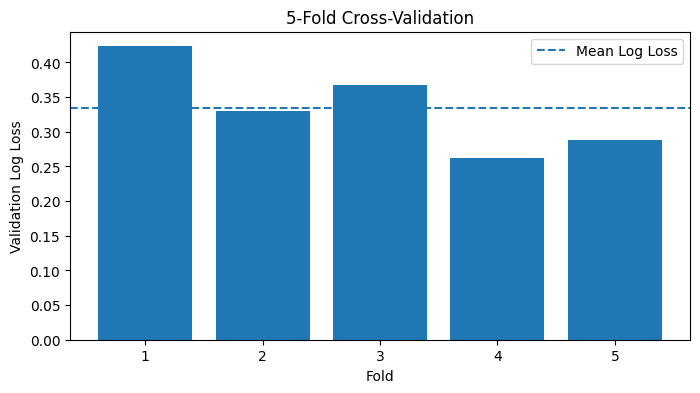

In [10]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))

plt.bar(results_df["fold"], results_df["log_loss"])
plt.axhline(
    results_df["log_loss"].mean(),
    linestyle="--",
    label="Mean Log Loss"
)

plt.xlabel("Fold")
plt.ylabel("Validation Log Loss")
plt.title("5-Fold Cross-Validation")
plt.legend()
plt.show()

In [15]:
fold_results = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X, y), start=1
):
    print(f"\n===== Fold {fold}/5 =====")

    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)

    # 1. Split
    X_tr = X[train_idx].copy()
    X_va = X[val_idx].copy()
    y_tr = y[train_idx]
    y_va = y[val_idx]

    # 2. Standardization: training fold only
    mean = X_tr.mean(axis=(0, 2, 3), keepdims=True)
    std = X_tr.std(axis=(0, 2, 3), keepdims=True)

    X_tr = (X_tr - mean) / (std + 1e-8)
    X_va = (X_va - mean) / (std + 1e-8)

    # 3. DataLoaders
    train_data = AugmentedDataset(X_tr, y_tr)
    val_data = TensorDataset(
        torch.from_numpy(X_va),
        torch.from_numpy(y_va)
    )

    train_loader = DataLoader(
        train_data, batch_size=32, shuffle=True
    )
    val_loader = DataLoader(
        val_data, batch_size=32, shuffle=False
    )

    # 4. New model for each fold
    model = IcebergCNNDropout().to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.001,
        weight_decay=0.0
    )
    criterion = torch.nn.CrossEntropyLoss()

    best_loss = float("inf")
    best_state = None
    best_epoch = 0
    wait = 0

    # 5. Training
    for epoch in range(40):
        model.train()

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        # 6. Validation
        model.eval()
        total_loss = 0.0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                total_loss += loss.item() * len(labels)

        val_loss = total_loss / len(val_data)

        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1

        if wait >= 6:
            break

    # 7. Restore best model
    model.load_state_dict(best_state)
    model.eval()

    probs = []
    with torch.no_grad():
        for images, _ in val_loader:
            outputs = model(images.to(device))
            p = torch.softmax(outputs, dim=1)[:, 1]
            probs.extend(p.cpu().numpy())

    probs = np.array(probs)

    fold_loss = log_loss(y_va, probs, labels=[0, 1])
    fold_accuracy = np.mean((probs >= 0.5) == y_va)

    fold_results.append({
        "fold": fold,
        "best_epoch": best_epoch,
        "log_loss": fold_loss,
        "accuracy": fold_accuracy
    })

    print(
        f"Best Epoch: {best_epoch} | "
        f"Log Loss: {fold_loss:.4f} | "
        f"Accuracy: {fold_accuracy:.2%}"
    )


===== Fold 1/5 =====
Best Epoch: 25 | Log Loss: 0.3079 | Accuracy: 87.85%

===== Fold 2/5 =====
Best Epoch: 17 | Log Loss: 0.3299 | Accuracy: 86.60%

===== Fold 3/5 =====
Best Epoch: 20 | Log Loss: 0.3670 | Accuracy: 81.93%

===== Fold 4/5 =====
Best Epoch: 19 | Log Loss: 0.2622 | Accuracy: 88.47%

===== Fold 5/5 =====
Best Epoch: 13 | Log Loss: 0.2943 | Accuracy: 87.50%


In [16]:
results_df = pd.DataFrame(fold_results)

print(results_df)

print(
    "\nMean Log Loss:",
    results_df["log_loss"].mean()
)

print(
    "Std Log Loss:",
    results_df["log_loss"].std()
)

print(
    "Mean Accuracy:",
    results_df["accuracy"].mean()
)

   fold  best_epoch  log_loss  accuracy
0     1          25  0.307907  0.878505
1     2          17  0.329857  0.866044
2     3          20  0.367031  0.819315
3     4          19  0.262178  0.884735
4     5          13  0.294291  0.875000

Mean Log Loss: 0.3122528910636902
Std Log Loss: 0.039241452030851436
Mean Accuracy: 0.8647196261682243


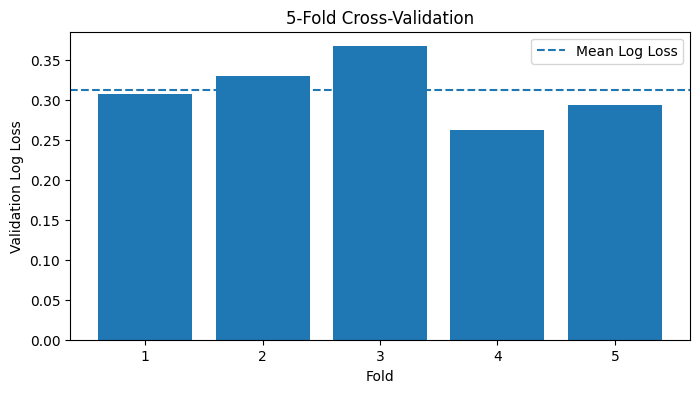

In [17]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))

plt.bar(results_df["fold"], results_df["log_loss"])
plt.axhline(
    results_df["log_loss"].mean(),
    linestyle="--",
    label="Mean Log Loss"
)

plt.xlabel("Fold")
plt.ylabel("Validation Log Loss")
plt.title("5-Fold Cross-Validation")
plt.legend()
plt.show()

In [18]:
results_cv40 = results_df.copy()
results_cv40.to_csv("cv_results_40epochs.csv", index=False)

print("Mean Log Loss:", results_cv40["log_loss"].mean())
print("Std Log Loss:", results_cv40["log_loss"].std())
print("Mean Accuracy:", results_cv40["accuracy"].mean())

Mean Log Loss: 0.3122528910636902
Std Log Loss: 0.039241452030851436
Mean Accuracy: 0.8647196261682243


## Incidence angle fusion: paired 5-fold comparison

Compare the existing image-only CNN with an image + incidence-angle CNN using the same stratified folds and training settings. Each training fold supplies the image normalization, angle median (for missing or nonnumeric values), angle mean, and angle standard deviation. Validation data use those fitted values; validation images are not augmented. The angle is concatenated with the 64 image features before the final output layer. Both variants use seed 42 per fold, AdamW (learning rate 0.001, weight decay 0), batch size 32, dropout 0.5, up to 40 epochs and patience 6. GPU is used when available.

The validation fold also selects the best epoch, and these folds are used to compare models, so reported scores can be optimistic for final model selection. A common seed does not force identical random sequences for different architectures. This is a paired comparison, not proof of generalization; use a separate test set or nested CV for an unbiased final assessment.


In [19]:
import copy
import random
from sklearn.metrics import log_loss
from torch.utils.data import Dataset, DataLoader, TensorDataset

# Coerce strings such as missing-value markers to NaN.
angles = pd.to_numeric(train["inc_angle"], errors="coerce").to_numpy(dtype=np.float32)
angles[~np.isfinite(angles)] = np.nan
print(f"Missing or nonnumeric incidence angles: {np.isnan(angles).sum()}")

class AugmentedAngleDataset(Dataset):
    def __init__(self, images, angle_values, labels):
        self.image_data = AugmentedDataset(images, labels)
        self.angles = torch.from_numpy(angle_values).float()

    def __len__(self):
        return len(self.image_data)

    def __getitem__(self, index):
        image, label = self.image_data[index]
        return image, self.angles[index], label

class IcebergCNNWithAngle(IcebergCNNDropout):
    def __init__(self):
        super().__init__()
        # The original network produces 64 features before its last layer.
        self.classifier[-1] = nn.Linear(65, 2)

    def forward(self, images, angle_values):
        features = self.features(images)
        for layer in list(self.classifier.children())[:-1]:
            features = layer(features)
        return self.classifier[-1](torch.cat((features, angle_values), dim=1))


def prepare_angles(training_angles, validation_angles):
    """Fit imputation and scaling on the training fold only."""
    observed = training_angles[np.isfinite(training_angles)]
    if not len(observed):
        raise ValueError("Training fold has no valid incidence angles.")
    median = float(np.median(observed))
    tr = np.where(np.isfinite(training_angles), training_angles, median)
    va = np.where(np.isfinite(validation_angles), validation_angles, median)
    mean = float(tr.mean())
    std = float(tr.std())
    if std < 1e-8:
        std = 1.0
    return ((tr - mean) / std).astype(np.float32).reshape(-1, 1), ((va - mean) / std).astype(np.float32).reshape(-1, 1), {"median": median, "mean": mean, "std": std}


def compare_angle_cv(use_angle):
    results = []
    oof_probabilities = np.empty(len(y), dtype=np.float32)
    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
        print(f"\n{'Fusion' if use_angle else 'Image-only'} | Fold {fold}/5", flush=True)
        random.seed(42)
        np.random.seed(42)
        torch.manual_seed(42)
        X_tr, X_va = X[train_idx].copy(), X[val_idx].copy()
        y_tr, y_va = y[train_idx], y[val_idx]
        image_mean = X_tr.mean(axis=(0, 2, 3), keepdims=True)
        image_std = X_tr.std(axis=(0, 2, 3), keepdims=True)
        X_tr = (X_tr - image_mean) / (image_std + 1e-8)
        X_va = (X_va - image_mean) / (image_std + 1e-8)
        if use_angle:
            a_tr, a_va, angle_stats = prepare_angles(angles[train_idx], angles[val_idx])
            train_data = AugmentedAngleDataset(X_tr, a_tr, y_tr)
            val_data = TensorDataset(torch.from_numpy(X_va), torch.from_numpy(a_va), torch.from_numpy(y_va))
            model = IcebergCNNWithAngle().to(device)
            print(f"  Training-fold angle median={angle_stats['median']:.4f}, mean={angle_stats['mean']:.4f}, std={angle_stats['std']:.4f}", flush=True)
        else:
            train_data = AugmentedDataset(X_tr, y_tr)
            val_data = TensorDataset(torch.from_numpy(X_va), torch.from_numpy(y_va))
            model = IcebergCNNDropout().to(device)
        train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
        val_loader = DataLoader(val_data, batch_size=32, shuffle=False)
        optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.0)
        criterion = nn.CrossEntropyLoss()
        best_loss, best_epoch, best_state, wait = float('inf'), 0, None, 0

        for epoch in range(40):
            model.train()
            for batch in train_loader:
                images = batch[0].to(device)
                labels = batch[-1].to(device)
                optimizer.zero_grad()
                outputs = model(images, batch[1].to(device)) if use_angle else model(images)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
            model.eval()
            total_loss = 0.0
            with torch.no_grad():
                for batch in val_loader:
                    images, labels = batch[0].to(device), batch[-1].to(device)
                    outputs = model(images, batch[1].to(device)) if use_angle else model(images)
                    total_loss += criterion(outputs, labels).item() * len(labels)
            val_loss = total_loss / len(val_data)
            if val_loss < best_loss:
                best_loss, best_epoch = val_loss, epoch + 1
                best_state = copy.deepcopy(model.state_dict())
                wait = 0
            else:
                wait += 1
            if wait >= 6:
                break

        model.load_state_dict(best_state)
        model.eval()
        probs = []
        with torch.no_grad():
            for batch in val_loader:
                images = batch[0].to(device)
                outputs = model(images, batch[1].to(device)) if use_angle else model(images)
                probs.extend(torch.softmax(outputs, dim=1)[:, 1].cpu().numpy())
        probs = np.asarray(probs)
        oof_probabilities[val_idx] = probs
        fold_loss = log_loss(y_va, probs, labels=[0, 1])
        fold_accuracy = np.mean((probs >= 0.5) == y_va)
        results.append({"fold": fold, "best_epoch": best_epoch, "log_loss": fold_loss, "accuracy": fold_accuracy})
        print(f"  Best epoch: {best_epoch} | Log loss: {fold_loss:.4f} | Accuracy: {fold_accuracy:.2%}", flush=True)
    return pd.DataFrame(results), oof_probabilities


Missing or nonnumeric incidence angles: 133


In [20]:
image_results, image_oof = compare_angle_cv(use_angle=False)
fusion_results, fusion_oof = compare_angle_cv(use_angle=True)

comparison = image_results.merge(fusion_results, on="fold", suffixes=("_image", "_fusion"))
print("\nPaired fold results:")
print(comparison.to_string(index=False))
for label, frame, probabilities in [("Image-only", image_results, image_oof), ("Fusion", fusion_results, fusion_oof)]:
    print(f"{label}: mean fold log loss={frame['log_loss'].mean():.4f}, "
          f"mean fold accuracy={frame['accuracy'].mean():.2%}, "
          f"pooled OOF log loss={log_loss(y, probabilities, labels=[0, 1]):.4f}")
print("Validation folds select both the best epoch and the comparison; interpret scores accordingly.")



Image-only | Fold 1/5
  Best epoch: 25 | Log loss: 0.3079 | Accuracy: 87.85%

Image-only | Fold 2/5
  Best epoch: 17 | Log loss: 0.3299 | Accuracy: 86.60%

Image-only | Fold 3/5
  Best epoch: 20 | Log loss: 0.3670 | Accuracy: 81.93%

Image-only | Fold 4/5
  Best epoch: 19 | Log loss: 0.2622 | Accuracy: 88.47%

Image-only | Fold 5/5
  Best epoch: 14 | Log loss: 0.2846 | Accuracy: 87.81%

Fusion | Fold 1/5
  Training-fold angle median=39.5479, mean=39.3270, std=3.6865
  Best epoch: 25 | Log loss: 0.3342 | Accuracy: 86.92%

Fusion | Fold 2/5
  Training-fold angle median=39.4991, mean=39.2780, std=3.6676
  Best epoch: 17 | Log loss: 0.3039 | Accuracy: 88.79%

Fusion | Fold 3/5
  Training-fold angle median=39.2340, mean=39.2769, std=3.6550
  Best epoch: 19 | Log loss: 0.3287 | Accuracy: 85.98%

Fusion | Fold 4/5
  Training-fold angle median=39.5095, mean=39.2798, std=3.6984
  Best epoch: 17 | Log loss: 0.2856 | Accuracy: 88.16%

Fusion | Fold 5/5
  Training-fold angle median=39.2340, mean=

### Observed GPU run (2026-10-31)

The comparison cells above were executed in a separate GPU process. The table records that run; execute the cells in this notebook to populate its live variables and outputs. Values below are rounded.

| Fold | Image-only log loss | Image-only accuracy | Fusion log loss | Fusion accuracy |
| --- | ---: | ---: | ---: | ---: |
| 1 | 0.3079 | 87.85% | 0.3342 | 86.92% |
| 2 | 0.3299 | 86.60% | 0.3039 | 88.79% |
| 3 | 0.3670 | 81.93% | 0.3287 | 85.98% |
| 4 | 0.2622 | 88.47% | 0.2856 | 88.16% |
| 5 | 0.2933 | 86.88% | 0.3075 | 86.56% |
| Mean across folds | 0.3120 | 86.35% | 0.3120 | 87.28% |

The mean fold log losses are equal at four decimal places; fusion has higher mean fold accuracy in this run. Fusion improves log loss on folds 2 and 3 and worsens it on folds 1, 4 and 5. This single seeded comparison does not establish a reliable improvement. The pooled out-of-fold log losses are 0.3121 (image-only) and 0.3120 (fusion); pooled and unweighted fold means differ slightly because fold sizes differ. Validation folds were also used for early stopping and model comparison, so these estimates can be optimistic. The earlier saved image-only run has mean loss 0.3123; small changes can occur across GPU runs despite the same seed.


## Stability check: two additional split seeds

The earlier paired comparison used split seed 42. This check repeats both models with split seeds 123 and 2024. Within each seed, the two models use identical stratified folds and the same existing training and fold-specific preprocessing as above. Training seeds remain 42 per fold. Execute cells 0–3 and the fusion definitions cell before running this experiment; the earlier training cells do not need to be rerun.

The reported fold standard deviations describe variation among these particular folds; folds share training data and are not independent. Only three split seeds in total are examined. Each validation fold selects the best epoch and is used for comparison, so results may be optimistic and do not support a strong statistical claim. The saved output below was produced in a separate GPU process; rerun this cell to populate variables in the current notebook kernel.


In [1]:
# Same folds per pair; change the split seed only, preserving the original splitter.
original_skf = skf
stability_fold_results = []
stability_oof = {}
try:
    for split_seed in (123, 2024):
        skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=split_seed)
        print(f"\n========== Split seed {split_seed} ==========", flush=True)
        for label, use_angle in (("Image-only", False), ("Fusion", True)):
            fold_frame, probabilities = compare_angle_cv(use_angle=use_angle)
            fold_frame.insert(0, "model", label)
            fold_frame.insert(0, "split_seed", split_seed)
            stability_fold_results.append(fold_frame)
            stability_oof[(split_seed, label)] = probabilities
finally:
    skf = original_skf

stability_results = pd.concat(stability_fold_results, ignore_index=True)
print("\nAll fold results:")
print(stability_results.to_string(index=False))
stability_summary = stability_results.groupby(["split_seed", "model"], sort=False).agg(
    mean_log_loss=("log_loss", "mean"),
    std_fold_log_loss=("log_loss", "std"),
    mean_accuracy=("accuracy", "mean"),
    std_fold_accuracy=("accuracy", "std"),
).reset_index()
print("\nSummary (standard deviations describe folds):")
print(stability_summary.to_string(index=False))
for seed in (123, 2024):
    for label in ("Image-only", "Fusion"):
        print(f"Seed {seed}, {label}: pooled OOF log loss="
              f"{log_loss(y, stability_oof[(seed, label)], labels=[0, 1]):.6f}")


NameError: name 'skf' is not defined

### Stability results and interpretation

These results were obtained on GPU in a separate process using the same code. Each entry is the mean of five validation folds; the table includes the previously recorded seed 42 run for context.

| Split seed | Image-only log loss | Fusion log loss | Image-only accuracy | Fusion accuracy |
| --- | ---: | ---: | ---: | ---: |
| 42 | 0.3120 | 0.3120 | 86.35% | 87.28% |
| 123 | 0.3093 | 0.3240 | 87.47% | 85.16% |
| 2024 | 0.2993 | 0.2994 | 86.91% | 87.03% |

At seed 123, fusion has higher log loss and lower accuracy; at seed 2024 the mean log losses are very close and fusion has slightly higher accuracy. The seed 42 log losses were equal to four displayed decimal places. These three split seeds do not show a consistent fusion advantage.

For seeds 123 and 2024 respectively, image-only fold log-loss standard deviations are 0.0314 and 0.0265; fusion values are 0.0378 and 0.0121. These describe fold variation for the chosen splits and are not independent-sample uncertainty estimates. Training folds overlap, the same validation fold determines early stopping and comparison, and only one training seed per fold was used. Repeat training seeds or use nested CV / an untouched test set for a stronger assessment; GPU operations can also introduce run-to-run variation.


## Image-only learning curves for split seeds 123 and 2024

The earlier 04 runs saved fold metrics but did not retain per-epoch losses. This section reruns the original 04 image-only model with dropout 0.5 and AdamW weight decay 0.0, horizontal/vertical augmentation, learning rate 0.001, batch size 32, a 40-epoch limit, patience 6 and training seed 42 per fold. Each split uses 5-fold stratification with shuffling; channel normalization is fitted only on that fold's training data. Validation data are not augmented.

The resulting ten graphs show training and validation loss in a 2 × 5 layout matching the candidate-model figures in 05. Each dashed line marks the best validation epoch. The 05 candidate has a third convolution block and uses weight decay 1e-4, so the curves compare complete configurations. The axes are shared within each figure; check their scales when comparing separate figures. These are newly run GPU histories and can differ from earlier fold scores even with the same seed. Validation folds select checkpoints, and overlapping folds and a fixed training seed limit conclusions about generalization.


In [ ]:
import copy
import random
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold


def evaluate_baseline_with_history(train_idx, val_idx):
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    X_tr, X_va = X[train_idx].copy(), X[val_idx].copy()
    y_tr, y_va = y[train_idx], y[val_idx]
    # Fit the channel statistics on the training fold only.
    mean = X_tr.mean(axis=(0, 2, 3), keepdims=True)
    std = X_tr.std(axis=(0, 2, 3), keepdims=True)
    X_tr = (X_tr - mean) / (std + 1e-8)
    X_va = (X_va - mean) / (std + 1e-8)
    training = AugmentedDataset(X_tr, y_tr)
    validation = TensorDataset(torch.from_numpy(X_va), torch.from_numpy(y_va))
    train_loader = DataLoader(training, batch_size=32, shuffle=True)
    val_loader = DataLoader(validation, batch_size=32, shuffle=False)
    model = IcebergCNNDropout().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.0)
    criterion = nn.CrossEntropyLoss()
    best_loss, best_epoch, best_state, wait = float("inf"), 0, None, 0
    train_losses, val_losses = [], []
    for epoch in range(40):
        model.train()
        train_loss_sum = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(labels)
        train_losses.append(train_loss_sum / len(training))
        model.eval()
        val_loss_sum = 0.0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                val_loss_sum += criterion(model(images), labels).item() * len(labels)
        val_loss = val_loss_sum / len(validation)
        val_losses.append(val_loss)
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
        if wait >= 6:
            break
    model.load_state_dict(best_state)
    model.eval()
    probs = []
    with torch.no_grad():
        for images, _ in val_loader:
            probs.extend(torch.softmax(model(images.to(device)), dim=1)[:, 1].cpu().numpy())
    probs = np.asarray(probs)
    return {"best_epoch": best_epoch, "log_loss": log_loss(y_va, probs, labels=[0, 1]),
            "accuracy": float(np.mean((probs >= 0.5) == y_va)),
            "train_losses": train_losses, "val_losses": val_losses}, probs


In [ ]:
baseline_curve_results = []
baseline_curve_histories = {}
baseline_curve_oof = {}
for split_seed in (123, 2024):
    splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=split_seed)
    oof = np.empty(len(y), dtype=np.float32)
    for fold, (train_idx, val_idx) in enumerate(splitter.split(X, y), 1):
        assert len(np.intersect1d(train_idx, val_idx)) == 0
        result, probabilities = evaluate_baseline_with_history(train_idx, val_idx)
        baseline_curve_histories[(split_seed, fold)] = result
        oof[val_idx] = probabilities
        baseline_curve_results.append({"split_seed": split_seed, "fold": fold,
                                  "best_epoch": result["best_epoch"],
                                  "log_loss": result["log_loss"], "accuracy": result["accuracy"]})
        print(f"Seed {split_seed} | fold {fold}: epoch {result['best_epoch']}, "
              f"log loss {result['log_loss']:.6f}, accuracy {result['accuracy']:.4%}", flush=True)
    baseline_curve_oof[split_seed] = oof
baseline_curve_df = pd.DataFrame(baseline_curve_results)
print("\nPer-fold results:")
print(baseline_curve_df.to_string(index=False))
baseline_curve_summary = baseline_curve_df.groupby("split_seed").agg(
    mean_log_loss=("log_loss", "mean"), std_fold_log_loss=("log_loss", "std"),
    mean_accuracy=("accuracy", "mean"), std_fold_accuracy=("accuracy", "std"))
print("\nSummary (fold standard deviations are descriptive):")
print(baseline_curve_summary.to_string())
for seed in (123, 2024):
    print(f"Seed {seed} pooled OOF log loss: {log_loss(y, baseline_curve_oof[seed], labels=[0, 1]):.6f}")


Seed 123 | fold 1: epoch 30, log loss 0.302551, accuracy 87.5389%
Seed 123 | fold 2: epoch 14, log loss 0.350130, accuracy 85.9813%
Seed 123 | fold 3: epoch 26, log loss 0.329560, accuracy 87.2274%
Seed 123 | fold 4: epoch 23, log loss 0.295655, accuracy 86.9159%
Seed 123 | fold 5: epoch 25, log loss 0.262899, accuracy 88.1250%
Seed 2024 | fold 1: epoch 20, log loss 0.293881, accuracy 88.1620%
Seed 2024 | fold 2: epoch 31, log loss 0.263470, accuracy 88.4735%
Seed 2024 | fold 3: epoch 31, log loss 0.293366, accuracy 87.2274%
Seed 2024 | fold 4: epoch 18, log loss 0.309589, accuracy 86.2928%
Seed 2024 | fold 5: epoch 26, log loss 0.322204, accuracy 84.3750%

Per-fold results:
 split_seed  fold  best_epoch  log_loss  accuracy
        123     1          30  0.302551  0.875389
        123     2          14  0.350130  0.859813
        123     3          26  0.329560  0.872274
        123     4          23  0.295655  0.869159
        123     5          25  0.262899  0.881250
       2024     

To redraw the saved figure without retraining, run the imports/data cell (cell 0), this restoration cell, and the plotting cell below.


In [ ]:
import matplotlib.pyplot as plt
# Saved GPU run: full-precision histories used in the figure.
# If the training cell has already run in this kernel, keep its newer data.
_saved_baseline_curve_histories = {(123, 1): {'best_epoch': 30, 'log_loss': 0.30255070328712463, 'accuracy': 0.8753894080996885, 'train_losses': [0.675935944355008, 0.6209156284644468, 0.5820237216964329, 0.531891024609794, 0.5019949900853105, 0.48864304197085434, 0.47890880246322226, 0.42475591213184694, 0.4046297443163925, 0.396892848290323, 0.37837618173608906, 0.360420393263188, 0.34226594731757537, 0.34014994818905975, 0.3065928204692116, 0.29019138929777727, 0.29370044429067144, 0.273339968717665, 0.3155871278207839, 0.2560600110867575, 0.29636528347027274, 0.24689660278829112, 0.22897123180138163, 0.24381862403077253, 0.2231363936015989, 0.19861509443049494, 0.22721274623346813, 0.19532426505328526, 0.1839002714523594, 0.17993179197326617, 0.17083303519870885, 0.20506129120581798, 0.17837797686027904, 0.17318783367135426, 0.14390363637575718, 0.12926529776464657], 'val_losses': [0.6037905936671938, 0.5709570870035534, 0.5672109625606894, 0.4722165200754861, 0.5171459867761142, 0.47025668105789437, 0.40762029798277816, 0.4250202613978464, 0.4246337959714048, 0.42460941841297806, 0.39150514753065374, 0.44142444348332655, 0.3957929807291526, 0.34233406114586373, 0.3318753133577257, 0.34132806634794444, 0.3566163399451154, 0.5075574076855613, 0.32089006345185256, 0.3395953535441762, 0.3179212250859938, 0.32152162144842594, 0.3293352463417556, 0.3114649569702761, 0.30441738811620395, 0.3187034918035952, 0.3196284358166274, 0.31859884119876936, 0.31617952694222795, 0.30255064480819066, 0.3347706541802003, 0.340908700962931, 0.3437456401917979, 0.32965573138191806, 0.32904947381589933, 0.38969924697809133]}, (123, 2): {'best_epoch': 14, 'log_loss': 0.35012978315353394, 'accuracy': 0.8598130841121495, 'train_losses': [0.6810981301897128, 0.6176203458641808, 0.580704351769512, 0.5445166253430344, 0.48916531900642257, 0.4831785656517591, 0.4325238686005584, 0.41357137960841295, 0.3715202552865282, 0.36953043344191805, 0.321531569572138, 0.33996520549151826, 0.33751570080883875, 0.2916990657593251, 0.2687061308249425, 0.2820757683119733, 0.2822364128586006, 0.24659130556199668, 0.24473687664940313, 0.2850906082827508], 'val_losses': [0.6253872610326868, 0.58682006950319, 0.564031637531946, 0.5108983147645665, 0.4736562632488499, 0.5119392631395584, 0.4870370821388129, 0.39936843116019166, 0.3978344208135297, 0.39600163058546806, 0.37133350335511256, 0.3752896053893067, 0.38344370902115565, 0.3501297876997155, 0.36832862888095574, 0.49770496196093184, 0.3686910236502397, 0.36083485924171954, 0.3548147715463588, 0.3503995485914069]}, (123, 3): {'best_epoch': 26, 'log_loss': 0.3295595943927765, 'accuracy': 0.8722741433021807, 'train_losses': [0.6642723104401854, 0.6083322273783636, 0.5721182517027911, 0.5372291853998382, 0.49286055023653474, 0.4447784808261824, 0.40972232757047666, 0.42378486354928974, 0.42123914359606346, 0.3538226305709648, 0.3611891743315446, 0.3473020168551224, 0.35730608633413785, 0.29724193497365653, 0.2936081730311305, 0.2538405212712353, 0.26328129691252555, 0.2426028625628768, 0.24214569127894153, 0.24734936788132297, 0.19670212758953276, 0.20444621662562096, 0.21762384122363868, 0.1877808554311423, 0.18342667989961262, 0.21682736063876937, 0.15815773613849657, 0.1467350731013649, 0.15035328930439842, 0.12959078950800193, 0.31524553425778473, 0.16055476384430498], 'val_losses': [0.644736878597105, 0.627206563949585, 0.5929713707846644, 0.5433887250698244, 0.4931469832625345, 0.4746143450246793, 0.4607597051008468, 0.5851902486379272, 0.41517818326890654, 0.4076251589991965, 0.4561255245565254, 0.41080065846814545, 0.37901720116814347, 0.35742421726757123, 0.3621529126278708, 0.5007052867212028, 0.365903553190261, 0.3492343016316958, 0.34940513040046456, 0.38329847505159464, 0.34335626845140693, 0.36538995612076136, 0.4083747391435216, 0.37825842596288783, 0.3721655122587614, 0.3295595721106663, 0.3594782530704391, 0.38917052393019014, 0.37439677671665716, 0.4886521736850434, 0.3427386329831364, 0.3741118840153715]}, (123, 4): {'best_epoch': 23, 'log_loss': 0.2956545054912567, 'accuracy': 0.8691588785046729, 'train_losses': [0.6611932316331871, 0.6019967358649381, 0.5626578922858948, 0.5166535353344675, 0.5058248750836424, 0.4440705574125586, 0.41163773283025573, 0.41324198984672383, 0.3995632634716673, 0.3772241513848026, 0.3381015205420467, 0.30906365336799474, 0.2956538442565841, 0.2893929913558722, 0.2806177915118211, 0.24658621285496887, 0.31109174087190666, 0.2848554744747404, 0.23266534378355774, 0.25358129950677244, 0.2076068717060104, 0.23908512532385828, 0.20639080942164895, 0.17577502118686356, 0.18911423357036647, 0.1892535397761145, 0.15386839990888085, 0.14408585188194634, 0.17263841183038772], 'val_losses': [0.6346473178573858, 0.5745387653881144, 0.5240453555947895, 0.5542637970867187, 0.4659529534455772, 0.44103535471304184, 0.39792574835343525, 0.43883006958250315, 0.39040028248156344, 0.3545579583938248, 0.3240961471450663, 0.32975809807625145, 0.32210401018553436, 0.3220051131922044, 0.305068168272714, 0.3175571702211817, 0.3222793351591933, 0.3042275798840686, 0.298146692391868, 0.30577792129783987, 0.30182818803831796, 0.29963533962986827, 0.29565449417031997, 0.3161284172141524, 0.3130208261701281, 0.32178285403769735, 0.3110475515209811, 0.4172565832743537, 0.31336755675265154]}, (123, 5): {'best_epoch': 25, 'log_loss': 0.2628987729549408, 'accuracy': 0.88125, 'train_losses': [0.6875495710105539, 0.6249714116812495, 0.5777366459369659, 0.5187698604533234, 0.4681513526729334, 0.42943426103235405, 0.4136329395377376, 0.39640134275887984, 0.39595087666377843, 0.3723573309145984, 0.3532399732004445, 0.3418659617503484, 0.31537504489548107, 0.285770341986065, 0.32684611457159213, 0.26806969222296434, 0.2742192488616315, 0.23861302207934892, 0.2363851736082095, 0.23600594436523514, 0.21686929229913843, 0.20935068100783683, 0.17786854988317996, 0.19301090540358581, 0.20264181870723438, 0.18560894200363634, 0.17060871144924952, 0.1630658349515493, 0.14815842349813363, 0.1291203410176102, 0.1426085114966486], 'val_losses': [0.6151932835578918, 0.560947185754776, 0.5143166929483414, 0.4716074734926224, 0.4015082210302353, 0.4097677022218704, 0.39960910379886627, 0.3687426894903183, 0.3914699852466583, 0.36184974312782286, 0.39243635833263396, 0.33086755871772766, 0.31539703011512754, 0.3202991485595703, 0.31593375355005265, 0.27812593430280685, 0.35705851167440417, 0.3011596515774727, 0.2903416931629181, 0.2958662316203117, 0.26484705954790116, 0.29117069244384763, 0.3272307276725769, 0.2775313198566437, 0.262898775935173, 0.26449479460716246, 0.3613185375928879, 0.28382287323474886, 0.2725253954529762, 0.2680219799280167, 0.27657109349966047]}, (2024, 1): {'best_epoch': 20, 'log_loss': 0.29388076066970825, 'accuracy': 0.881619937694704, 'train_losses': [0.7089853003818545, 0.6508504855660656, 0.6236409999296615, 0.6009944433916944, 0.568215989128092, 0.5344594414589094, 0.49752514811112186, 0.4749920226964557, 0.4483733601920417, 0.4145155955085695, 0.4289784211017894, 0.39464629432534915, 0.3643939544912065, 0.36494681692086245, 0.37916314258114586, 0.335590253844683, 0.3190493441520031, 0.35906245033906387, 0.3053190863211454, 0.29513135994911566, 0.3030059843419217, 0.2983636574083627, 0.2737236448729865, 0.2480418661424915, 0.25182764058815066, 0.23811500200701244], 'val_losses': [0.6389473437148834, 0.5948764633538196, 0.5691323819979329, 0.5521343721662912, 0.5168401727516703, 0.45473744644206077, 0.4095538529462973, 0.438059191791068, 0.39065359917638326, 0.37242768343677307, 0.36311729783329183, 0.35027074813808773, 0.3332666477397544, 0.3118017863630017, 0.3493637985613696, 0.30185164543587445, 0.36134969814328916, 0.32681756338654133, 0.30341487027098113, 0.2938807589984537, 0.3019546006632433, 0.3075337996687327, 0.33469526604328464, 0.3808732626965484, 0.34972831876107097, 0.36908135161592953]}, (2024, 2): {'best_epoch': 31, 'log_loss': 0.2634699046611786, 'accuracy': 0.8847352024922118, 'train_losses': [0.7142454500971412, 0.6499647933899753, 0.6131098965416638, 0.5843830679602113, 0.533321727790223, 0.5350246033859922, 0.47208494747047397, 0.44264322154613, 0.4360466218805369, 0.43205640708921667, 0.40012298560384096, 0.3741068153621067, 0.3844286561802041, 0.3401617205245181, 0.3413812958069918, 0.3814609133793057, 0.3238707083108271, 0.3138010769301956, 0.28433495756039623, 0.268221251149709, 0.2879336294794306, 0.2647531967746589, 0.30583867122907704, 0.2765914675600345, 0.27908931823559135, 0.2266535807752275, 0.23670208969807494, 0.2942785309483925, 0.20959790138090761, 0.21666718951160768, 0.20979663628042441, 0.1867415171131063, 0.15532189739152313, 0.2010732308459858, 0.1585156545912945, 0.13588773852921238, 0.14398288449224605], 'val_losses': [0.6259099481818832, 0.603081967971778, 0.5582235179771887, 0.5274189239907487, 0.5297185691346261, 0.46456253259352803, 0.42574420589895634, 0.412818550993906, 0.44713554761120095, 0.38742047140949243, 0.3463979241354072, 0.36338335482223755, 0.37672818514788264, 0.32350643331364864, 0.3269513037717231, 0.3306689505752559, 0.3003941238611194, 0.327479184869201, 0.30087486364388394, 0.35402374896380434, 0.2907289022962763, 0.3685844602836499, 0.30470499217603064, 0.3379342323691349, 0.2850240374395966, 0.35803365794436953, 0.30142536249615226, 0.29071558417746585, 0.307286801988787, 0.2799159826508091, 0.2634699161663489, 0.31553163147760654, 0.3196377471173501, 0.2850232143535328, 0.2895075540396318, 0.3293345308589903, 0.3570358152153127]}, (2024, 3): {'best_epoch': 31, 'log_loss': 0.2933656871318817, 'accuracy': 0.8722741433021807, 'train_losses': [0.6824996756187939, 0.626077227962268, 0.5934256745425408, 0.555899246168248, 0.5150119593760415, 0.49442800765658207, 0.4499497638488318, 0.4375823592173338, 0.43027701135361834, 0.36988068944016006, 0.42139839577842114, 0.39216051729786516, 0.3847388468119472, 0.35022578860574277, 0.3441216308254798, 0.3156964381226133, 0.3376167391485659, 0.36817185168422395, 0.31611905544589763, 0.3035185611106322, 0.2754859360093171, 0.2548909448406609, 0.27527666256842165, 0.2831076292534499, 0.27585854269389937, 0.24890337916546945, 0.23593129136324487, 0.22851050100111442, 0.22908107916637965, 0.2355553396772056, 0.20748283192573444, 0.20991312268183554, 0.1882680714891139, 0.20933585123261342, 0.1922925016969814, 0.1860056278859835, 0.1643758348014354], 'val_losses': [0.6228247015647056, 0.5968800415502531, 0.5690545172334831, 0.5384700162759822, 0.4856718942012371, 0.444654583745285, 0.4453790589842098, 0.4319737952817638, 0.3986617384298568, 0.43006496860230825, 0.3867173503121112, 0.4194774534843421, 0.36644596139961316, 0.3498505981540383, 0.3469177116857511, 0.3693044544009033, 0.3349604402375741, 0.34029240585933224, 0.33576694920055594, 0.3395967193853075, 0.3166152451454293, 0.3118379128127826, 0.31648336002759847, 0.35923346626424346, 0.31785938645077644, 0.32390658914857196, 0.2997055866079538, 0.3382356187264867, 0.3183295880894052, 0.3257043224257472, 0.2933656609968233, 0.2992220486621619, 0.3117300422392159, 0.3156138919409933, 0.310320978363355, 0.3120346719695029, 0.3341082412273713]}, (2024, 4): {'best_epoch': 18, 'log_loss': 0.3095885217189789, 'accuracy': 0.8629283489096573, 'train_losses': [0.6806920413290813, 0.6248316356472363, 0.6031645423531625, 0.5525971674305893, 0.5251076975931717, 0.5114754594032038, 0.4923111480469826, 0.44468333620348666, 0.4249350795825756, 0.4093025577481798, 0.4022986284941319, 0.37110850570356113, 0.3727981717509398, 0.3818682215683923, 0.32030943590880534, 0.3412959524085535, 0.3028453304457739, 0.3209204696995712, 0.32357349923273965, 0.3140285341236058, 0.319636424421242, 0.29199504531739934, 0.2762668900487949, 0.2525798483974564], 'val_losses': [0.6527444837249328, 0.6186122600905992, 0.5758896146979288, 0.5503143491774705, 0.5010087842881865, 0.5166344154289578, 0.4674039639045145, 0.43154009703163787, 0.40907440341521645, 0.3912082671005035, 0.41887656773362203, 0.3524975743249198, 0.3448141534751821, 0.34892513373187767, 0.33701220721099234, 0.3651454954689537, 0.3505971662909071, 0.30958850398613286, 0.33050505375936395, 0.35336347309599786, 0.31479060742713955, 0.31359883298012325, 0.3298603968456898, 0.37304199298965596]}, (2024, 5): {'best_epoch': 26, 'log_loss': 0.32220354676246643, 'accuracy': 0.84375, 'train_losses': [0.6667412110949602, 0.61191802028555, 0.5759176118908641, 0.5398257867755177, 0.5019135868809305, 0.46318267977497657, 0.45160327615024887, 0.40886073571127896, 0.3958516761521313, 0.38263961254993334, 0.35898266078155733, 0.35546543107968626, 0.3363381053474833, 0.31618025295459595, 0.31478753569173246, 0.2951699751559819, 0.29929006851722145, 0.281872208244704, 0.2816822743304422, 0.255108657470002, 0.2604124063271971, 0.2597810884363183, 0.24523605299515888, 0.21917583791080664, 0.2235379219983597, 0.2033921993595789, 0.17558084962152617, 0.16503870802876364, 0.18774396886706723, 0.18441793283105268, 0.14249202256262117, 0.13369476813764958], 'val_losses': [0.6488526821136474, 0.6361847877502441, 0.5826148331165314, 0.5549081563949585, 0.5107096374034882, 0.4742135554552078, 0.46875180304050446, 0.45652028918266296, 0.43121633529663084, 0.42407721281051636, 0.42416656017303467, 0.3726204738020897, 0.4252090141177177, 0.33614195287227633, 0.42406791299581525, 0.3362753242254257, 0.3434149414300919, 0.37546161711215975, 0.3318233907222748, 0.35597867518663406, 0.3782198131084442, 0.3354616746306419, 0.3547987133264542, 0.32931905537843703, 0.3240379586815834, 0.32220352739095687, 0.33525905907154085, 0.4544206902384758, 0.47616186290979384, 0.3667314380407333, 0.3743279665708542, 0.3554290682077408]}}
_saved_baseline_curve_rows = [{'split_seed': 123, 'fold': 1, 'best_epoch': 30, 'log_loss': 0.30255070328712463, 'accuracy': 0.8753894080996885}, {'split_seed': 123, 'fold': 2, 'best_epoch': 14, 'log_loss': 0.35012978315353394, 'accuracy': 0.8598130841121495}, {'split_seed': 123, 'fold': 3, 'best_epoch': 26, 'log_loss': 0.3295595943927765, 'accuracy': 0.8722741433021807}, {'split_seed': 123, 'fold': 4, 'best_epoch': 23, 'log_loss': 0.2956545054912567, 'accuracy': 0.8691588785046729}, {'split_seed': 123, 'fold': 5, 'best_epoch': 25, 'log_loss': 0.2628987729549408, 'accuracy': 0.88125}, {'split_seed': 2024, 'fold': 1, 'best_epoch': 20, 'log_loss': 0.29388076066970825, 'accuracy': 0.881619937694704}, {'split_seed': 2024, 'fold': 2, 'best_epoch': 31, 'log_loss': 0.2634699046611786, 'accuracy': 0.8847352024922118}, {'split_seed': 2024, 'fold': 3, 'best_epoch': 31, 'log_loss': 0.2933656871318817, 'accuracy': 0.8722741433021807}, {'split_seed': 2024, 'fold': 4, 'best_epoch': 18, 'log_loss': 0.3095885217189789, 'accuracy': 0.8629283489096573}, {'split_seed': 2024, 'fold': 5, 'best_epoch': 26, 'log_loss': 0.32220354676246643, 'accuracy': 0.84375}]
if "baseline_curve_histories" not in globals() or "baseline_curve_df" not in globals():
    baseline_curve_histories = _saved_baseline_curve_histories
    baseline_curve_df = pd.DataFrame(_saved_baseline_curve_rows)
    print("Using recorded GPU histories; no training run is needed for the plot.")
else:
    print("Using baseline histories from the current kernel.")


### Training and validation loss by fold

The vertical dashed line marks the epoch with the lowest validation loss.


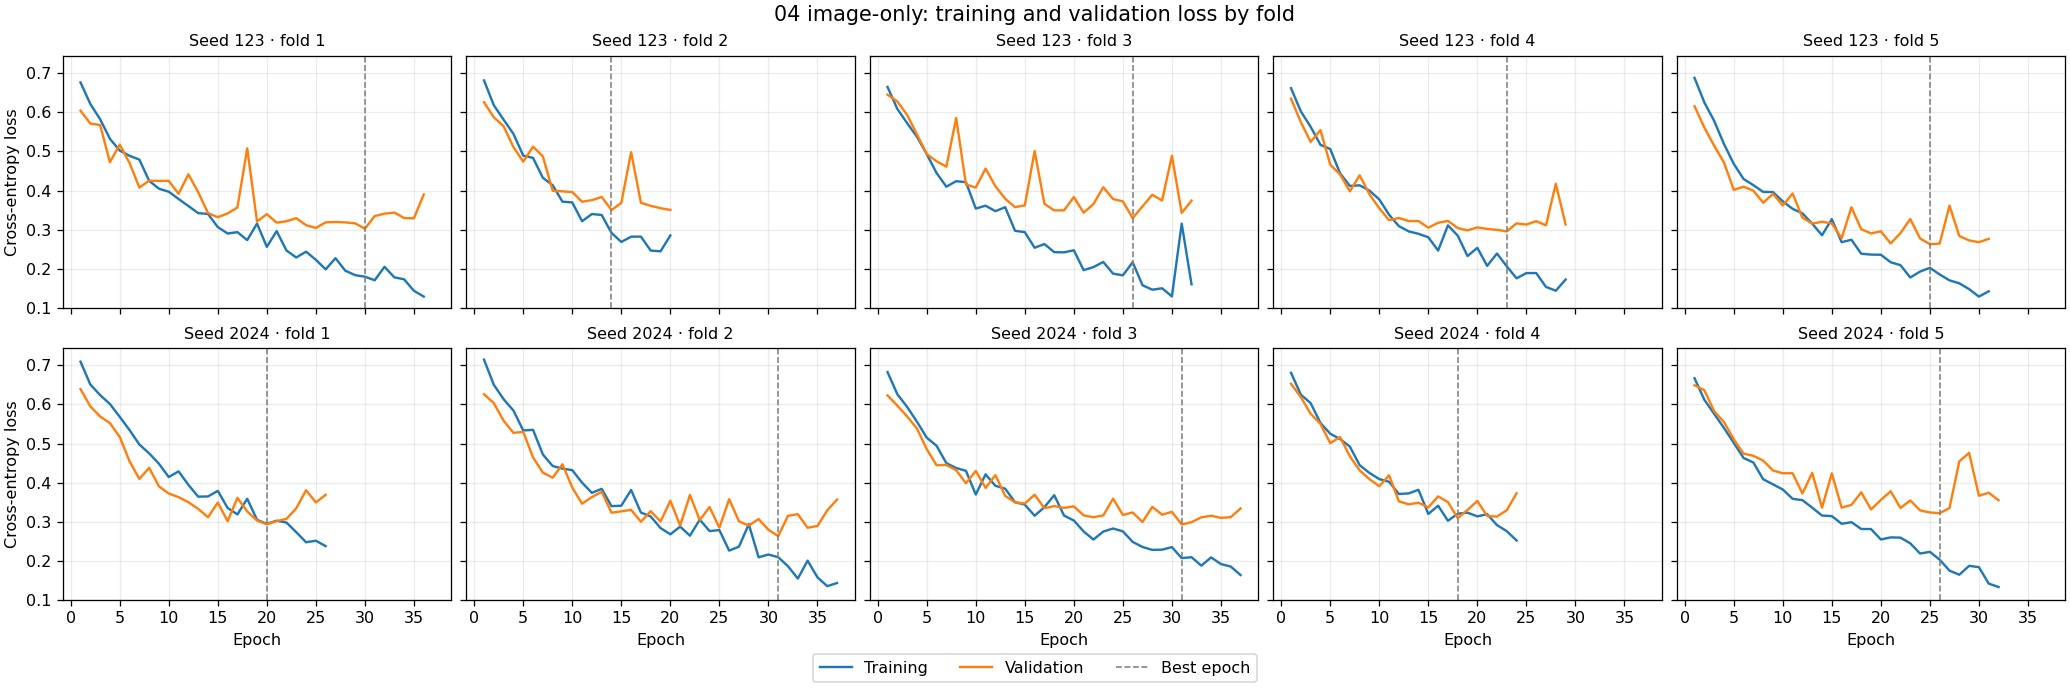

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6), sharex=True, sharey=True, constrained_layout=True)
for row, seed in enumerate((123, 2024)):
    for col in range(5):
        result = baseline_curve_histories[(seed, col + 1)]
        epochs = range(1, len(result["train_losses"]) + 1)
        ax = axes[row, col]
        ax.plot(epochs, result["train_losses"], label="Training", color="tab:blue")
        ax.plot(epochs, result["val_losses"], label="Validation", color="tab:orange")
        ax.axvline(result["best_epoch"], color="gray", linestyle="--", linewidth=1, label="Best epoch")
        ax.set_title(f"Seed {seed} · fold {col + 1}", fontsize=10)
        ax.grid(alpha=0.25)
        if row == 1:
            ax.set_xlabel("Epoch")
        if col == 0:
            ax.set_ylabel("Cross-entropy loss")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3)
fig.suptitle("04 image-only: training and validation loss by fold", fontsize=13)
plt.show()


### Observed GPU rerun

| Split seed | Mean fold log loss | Mean accuracy |
| --- | ---: | ---: |
| 123 | 0.3082 | 87.16% |
| 2024 | 0.2965 | 86.91% |

These are new reruns with full histories; the earlier stability table remains unchanged. Some folds show training loss falling while validation loss levels off or fluctuates, suggesting overfitting, although the pattern varies across folds. The 05 candidate uses a deeper model and different weight decay; compare the entire configurations, and check axis scales. Validation folds select the best epoch, folds share training data, and the training seed is fixed, so these curves do not establish a generalization guarantee.


## Image-only with weight decay 1e-4

This is a new run of the original two-convolution CNN with dropout 0.5 and AdamW weight decay 1e-4. The earlier no-weight-decay cells and curves remain unchanged. It uses the same seed-123 and seed-2024 stratified folds, augmentation, per-training-fold normalization, 40-epoch limit, patience 6, learning rate and training seed as the 05 candidate. Curves and metrics below are from this new GPU run. The same validation fold selects the best epoch and is reported; folds overlap and the scores can be optimistic.


In [ ]:
import copy
import random
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold


def evaluate_decay_with_history(train_idx, val_idx):
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    X_tr, X_va = X[train_idx].copy(), X[val_idx].copy()
    y_tr, y_va = y[train_idx], y[val_idx]
    # Fit the channel statistics on the training fold only.
    mean = X_tr.mean(axis=(0, 2, 3), keepdims=True)
    std = X_tr.std(axis=(0, 2, 3), keepdims=True)
    X_tr = (X_tr - mean) / (std + 1e-8)
    X_va = (X_va - mean) / (std + 1e-8)
    training = AugmentedDataset(X_tr, y_tr)
    validation = TensorDataset(torch.from_numpy(X_va), torch.from_numpy(y_va))
    train_loader = DataLoader(training, batch_size=32, shuffle=True)
    val_loader = DataLoader(validation, batch_size=32, shuffle=False)
    model = IcebergCNNDropout().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    best_loss, best_epoch, best_state, wait = float("inf"), 0, None, 0
    train_losses, val_losses = [], []
    for epoch in range(40):
        model.train()
        train_loss_sum = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(labels)
        train_losses.append(train_loss_sum / len(training))
        model.eval()
        val_loss_sum = 0.0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                val_loss_sum += criterion(model(images), labels).item() * len(labels)
        val_loss = val_loss_sum / len(validation)
        val_losses.append(val_loss)
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
        if wait >= 6:
            break
    model.load_state_dict(best_state)
    model.eval()
    probs = []
    with torch.no_grad():
        for images, _ in val_loader:
            probs.extend(torch.softmax(model(images.to(device)), dim=1)[:, 1].cpu().numpy())
    probs = np.asarray(probs)
    return {"best_epoch": best_epoch, "log_loss": log_loss(y_va, probs, labels=[0, 1]),
            "accuracy": float(np.mean((probs >= 0.5) == y_va)),
            "train_losses": train_losses, "val_losses": val_losses}, probs


In [ ]:
decay_curve_results = []
decay_curve_histories = {}
decay_curve_oof = {}
for split_seed in (123, 2024):
    splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=split_seed)
    oof = np.empty(len(y), dtype=np.float32)
    for fold, (train_idx, val_idx) in enumerate(splitter.split(X, y), 1):
        assert len(np.intersect1d(train_idx, val_idx)) == 0
        result, probabilities = evaluate_decay_with_history(train_idx, val_idx)
        decay_curve_histories[(split_seed, fold)] = result
        oof[val_idx] = probabilities
        decay_curve_results.append({"split_seed": split_seed, "fold": fold,
                                  "best_epoch": result["best_epoch"],
                                  "log_loss": result["log_loss"], "accuracy": result["accuracy"]})
        print(f"Seed {split_seed} | fold {fold}: epoch {result['best_epoch']}, "
              f"log loss {result['log_loss']:.6f}, accuracy {result['accuracy']:.4%}", flush=True)
    decay_curve_oof[split_seed] = oof
decay_curve_df = pd.DataFrame(decay_curve_results)
print("\nPer-fold results:")
print(decay_curve_df.to_string(index=False))
decay_curve_summary = decay_curve_df.groupby("split_seed").agg(
    mean_log_loss=("log_loss", "mean"), std_fold_log_loss=("log_loss", "std"),
    mean_accuracy=("accuracy", "mean"), std_fold_accuracy=("accuracy", "std"))
print("\nSummary (fold standard deviations are descriptive):")
print(decay_curve_summary.to_string())
for seed in (123, 2024):
    print(f"Seed {seed} pooled OOF log loss: {log_loss(y, decay_curve_oof[seed], labels=[0, 1]):.6f}")


Seed 123 | fold 1: epoch 28, log loss 0.310244, accuracy 88.1620%
Seed 123 | fold 2: epoch 15, log loss 0.348869, accuracy 85.6698%
Seed 123 | fold 3: epoch 18, log loss 0.339398, accuracy 84.4237%
Seed 123 | fold 4: epoch 19, log loss 0.282074, accuracy 86.9159%
Seed 123 | fold 5: epoch 26, log loss 0.274043, accuracy 89.6875%
Seed 2024 | fold 1: epoch 22, log loss 0.307756, accuracy 87.8505%
Seed 2024 | fold 2: epoch 26, log loss 0.276411, accuracy 88.1620%
Seed 2024 | fold 3: epoch 22, log loss 0.314049, accuracy 86.6044%
Seed 2024 | fold 4: epoch 32, log loss 0.299697, accuracy 89.0966%
Seed 2024 | fold 5: epoch 25, log loss 0.320674, accuracy 84.6875%

Per-fold results:
 split_seed  fold  best_epoch  log_loss  accuracy
        123     1          28  0.310244  0.881620
        123     2          15  0.348869  0.856698
        123     3          18  0.339398  0.844237
        123     4          19  0.282074  0.869159
        123     5          26  0.274043  0.896875
       2024     

### Restore recorded histories and draw curves

Run the restoration cell and plot cell to redraw without training.


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
_saved_decay_curve_histories = {(123, 1): {'best_epoch': 28, 'log_loss': 0.3102436363697052, 'accuracy': 0.881619937694704, 'train_losses': [0.6759275709709337, 0.6196803848258425, 0.5808271215655147, 0.5330412260322764, 0.508449756857574, 0.49945052489580255, 0.49441886995792017, 0.42894252944252775, 0.4272693108741139, 0.3918496220142509, 0.3703145794309124, 0.3555876790826802, 0.34154297642566595, 0.337656015479416, 0.3033461761185413, 0.31354186802032524, 0.3139062944483172, 0.28950106465807207, 0.3453809608555082, 0.26210344462587976, 0.2865039823360491, 0.254126827278271, 0.23393432928985297, 0.22306754266435247, 0.22168659444953534, 0.21972106852432943, 0.22137108189652696, 0.19517604557220952, 0.17381536266066, 0.17796981012243968, 0.16012356591440696, 0.2140993538979711, 0.1407117028245216, 0.16124725299840176], 'val_losses': [0.6036864537687688, 0.5672766150343826, 0.5614483547730609, 0.4739205775973953, 0.5152595288169532, 0.49763305666290714, 0.422321119551718, 0.411546084136235, 0.39816624140860135, 0.3875445124005603, 0.4011923541718183, 0.3773574478158327, 0.401336376158509, 0.35415354612460387, 0.3576012054556905, 0.37713808695150314, 0.3481352249874133, 0.42878863897763564, 0.3295258287328797, 0.3560338013129442, 0.3366909209244255, 0.3312669531159347, 0.3203073173929644, 0.34852700411832405, 0.32850277469336775, 0.35189715115864095, 0.3198760711410985, 0.3102436482246655, 0.3631044796314758, 0.3318465774910774, 0.33581440976089755, 0.3112416820501984, 0.36636296508839566, 0.32143802241845826]}, (123, 2): {'best_epoch': 15, 'log_loss': 0.348868727684021, 'accuracy': 0.8566978193146417, 'train_losses': [0.6810960312049461, 0.6176698779743905, 0.5800587815738524, 0.5412782084542331, 0.4870552620846874, 0.4743090184145576, 0.43440747813888575, 0.40493175468682685, 0.3850075071060555, 0.3638695344177894, 0.31847841272875377, 0.3232354233251915, 0.3405831022564081, 0.30121970159856026, 0.2526313707316679, 0.26962457958460784, 0.27698668098877116, 0.2814099856957921, 0.2363671590853555, 0.23314034079353232, 0.21316337281154266], 'val_losses': [0.625391674561664, 0.5869022923466573, 0.5656007563585062, 0.5075992002758282, 0.4755421815515493, 0.5074793166739175, 0.4497771741384626, 0.41435273634915376, 0.3964831187798514, 0.3923741236656474, 0.36979823356838476, 0.37562998209811505, 0.38303587521169613, 0.35365995173376075, 0.34886872136739044, 0.4467333566362612, 0.4022389750613211, 0.3786171396202002, 0.3572845080172408, 0.3673720051566148, 0.40927114553540667]}, (123, 3): {'best_epoch': 18, 'log_loss': 0.33939844369888306, 'accuracy': 0.8442367601246106, 'train_losses': [0.6641274311072364, 0.606726439967345, 0.5656114226194071, 0.5371183083100144, 0.4959260395561822, 0.425966631850505, 0.39074625712489114, 0.4058521174631914, 0.3756173046440792, 0.33500698841934035, 0.3427338646615936, 0.3452156531281148, 0.3169988536988026, 0.2759163562710733, 0.2866992242314903, 0.25412099086334716, 0.2604732499606704, 0.22063111402936403, 0.23318053386555238, 0.21274657280925466, 0.19372701375445442, 0.2002415015933482, 0.21072241102235678, 0.17753037782451275], 'val_losses': [0.6445231277994649, 0.6076493162975133, 0.5940981275196016, 0.5384459469548638, 0.48635980542575086, 0.46412227012658047, 0.4603159305091216, 0.5098497358809378, 0.42073627721483464, 0.39345881556424767, 0.41395972729471986, 0.37686356075827576, 0.4130647134186694, 0.37537444533774417, 0.3611658074402735, 0.4172753821652255, 0.35328402586072405, 0.3393984367821447, 0.38526569404334665, 0.36038138914702467, 0.35909378199005426, 0.3908862297037309, 0.412510921673797, 0.363977827387064]}, (123, 4): {'best_epoch': 19, 'log_loss': 0.28207382559776306, 'accuracy': 0.8691588785046729, 'train_losses': [0.6611681735710715, 0.6012951871982702, 0.5573576488071182, 0.5143551163996744, 0.4932970359329126, 0.44179805899539776, 0.4150735937517691, 0.41769480324311825, 0.3836814572545391, 0.41503001741385515, 0.35495515455748083, 0.3234034456597207, 0.31776311457888834, 0.3030707957869104, 0.2793068095797779, 0.27695378844661817, 0.29755517901360573, 0.2730757291207347, 0.22856731629195107, 0.2538949598791259, 0.2127572914305276, 0.2443154885819064, 0.1983394497005227, 0.18220263675424334, 0.18705163007008313], 'val_losses': [0.6345705076170116, 0.572074073404538, 0.518912284916435, 0.5153568286297848, 0.4589723969731375, 0.4163563308129058, 0.4142414225596134, 0.41965201225514726, 0.42140217432955346, 0.3609202802181244, 0.33354268044326163, 0.3557293980478126, 0.30977153290655013, 0.32282358189795246, 0.3067147631642069, 0.30072599558327984, 0.303650811627925, 0.2977338700186798, 0.28207385679852, 0.28740822444916514, 0.3255105905722235, 0.2955115428426509, 0.2922428201661355, 0.2922711590003234, 0.32268346900648415]}, (123, 5): {'best_epoch': 26, 'log_loss': 0.2740429937839508, 'accuracy': 0.896875, 'train_losses': [0.6875508702432627, 0.6250407413530201, 0.5823020255454233, 0.5190451236157403, 0.47458938757578534, 0.42233457799269775, 0.39985727019770495, 0.39160127784604226, 0.377388648897688, 0.3836053806673329, 0.3720710273843688, 0.35324932676609433, 0.3228761853876515, 0.28896279581982026, 0.28621639418082073, 0.2746431701279875, 0.2644087532274077, 0.23888991944886442, 0.23402725721816778, 0.24399921531292879, 0.22472593487701684, 0.2120117038790125, 0.17059664637128882, 0.18030280044238514, 0.1832865255644017, 0.21305493402332532, 0.18377320995304816, 0.171152022583091, 0.16105207269344002, 0.13688555457324625, 0.14792487625543296, 0.10544128750807771], 'val_losses': [0.615203458070755, 0.5600404411554336, 0.5154225856065751, 0.46257883310317993, 0.4200045943260193, 0.39801347255706787, 0.41209161281585693, 0.3522783577442169, 0.41984806060791013, 0.44140741527080535, 0.394417929649353, 0.3297373026609421, 0.32266730070114136, 0.2939877942204475, 0.2985956698656082, 0.27820328176021575, 0.3655483901500702, 0.2968397006392479, 0.2948307543992996, 0.2775947690010071, 0.2939717799425125, 0.3090301275253296, 0.28795825093984606, 0.2868517473340034, 0.28998241424560545, 0.2740429684519768, 0.32954998314380646, 0.315111044049263, 0.29818131774663925, 0.31098620891571044, 0.2912418834865093, 0.33492756485939024]}, (2024, 1): {'best_epoch': 22, 'log_loss': 0.3077559769153595, 'accuracy': 0.8785046728971962, 'train_losses': [0.7089852619617132, 0.6510208106003789, 0.6237618208210262, 0.6007521501157959, 0.5712080004153917, 0.5349213846103344, 0.4945010254370079, 0.4752382132009148, 0.44840592670886664, 0.40942111983024226, 0.3989675242340574, 0.3995486568000432, 0.35451608501368914, 0.3642209000124749, 0.3785397863583182, 0.32701515683371485, 0.3098429056786041, 0.3206142314643667, 0.3105754219547251, 0.29132241475673876, 0.28655956266847143, 0.2854119241005354, 0.2562463015480517, 0.2354708547970325, 0.24576419827093487, 0.22980203955134468, 0.23573266718876335, 0.23341643224910935], 'val_losses': [0.6389473431578306, 0.5952835936226949, 0.5745017236313344, 0.5551635934231437, 0.5227453465286259, 0.44753590218049716, 0.41977638662995836, 0.41061543360551256, 0.4024167765654798, 0.3696864422609648, 0.38393632716602993, 0.36581745065491744, 0.3536535706951332, 0.3361847289243852, 0.3618828733212306, 0.343797586417077, 0.31555630037772947, 0.33450032171786404, 0.3135329882300474, 0.3084990610583967, 0.3204568650365096, 0.3077559207454087, 0.41776480927274234, 0.3401016152907755, 0.3601793800930368, 0.4157936729003336, 0.35142387853578827, 0.3402150887937932]}, (2024, 2): {'best_epoch': 26, 'log_loss': 0.2764114439487457, 'accuracy': 0.881619937694704, 'train_losses': [0.7142455511881054, 0.6499576817149774, 0.6127567072446144, 0.5783033063889294, 0.5335747764989536, 0.5453646520525798, 0.47541309246214125, 0.4489001744860146, 0.4396606462594595, 0.43297734988137604, 0.4217580771037404, 0.3939176322609209, 0.4150861211219804, 0.35053651703816324, 0.35375660820483046, 0.3155811761773757, 0.3206861999266239, 0.3238879722330374, 0.30191902434602175, 0.2860302884111345, 0.27643726064605073, 0.26637470399320634, 0.24895301921436866, 0.22198827783646105, 0.24531363794000838, 0.22713324532133475, 0.22597098283161898, 0.3391991130287584, 0.22263965532125576, 0.22995066599207564, 0.19651326577491995, 0.18409129956887602], 'val_losses': [0.6259071590187394, 0.603096217659775, 0.5572127237498203, 0.5205631984914203, 0.518387129698587, 0.4781364022849876, 0.4327490687184616, 0.4025438632641997, 0.4283302639875085, 0.3884853524303882, 0.3593352776937581, 0.39266214642754965, 0.3549611288996129, 0.3128213245897464, 0.33266850507519324, 0.3133438308650738, 0.30606332772942346, 0.3510863156147835, 0.31952250486593753, 0.36044310850912353, 0.28360703930757775, 0.3159095947108467, 0.2963769151553558, 0.28639893010084594, 0.31670575223955966, 0.2764114231666161, 0.33458310139809394, 0.3121552005920826, 0.3045155583196131, 0.277224349631925, 0.29411310926108764, 0.30529264535905787]}, (2024, 3): {'best_epoch': 22, 'log_loss': 0.31404903531074524, 'accuracy': 0.8660436137071651, 'train_losses': [0.6824936707411905, 0.6260081612775777, 0.5932927082175866, 0.5552755949883748, 0.5164277140088873, 0.5013306751463995, 0.45444732142535393, 0.4506326594672348, 0.43941651892123146, 0.37854107468739584, 0.42278563540751174, 0.37542238804807165, 0.3666843292031173, 0.36643625551940684, 0.33989082775075086, 0.31292530645733224, 0.3237519437971286, 0.35413549620939805, 0.3220632705671984, 0.29344564938187506, 0.2756014437249928, 0.2617824014656635, 0.2609703199108968, 0.2771449732947703, 0.2802084703245204, 0.25205801595191146, 0.22754095233425162, 0.22996873058384504], 'val_losses': [0.6226981792865884, 0.597153500604481, 0.5705308834340342, 0.5465050389833539, 0.4828525348987163, 0.4510181939861856, 0.46587067229725493, 0.41356608188040905, 0.40316746743668647, 0.44517411435504567, 0.3850913719967518, 0.404557390469257, 0.36413020963238035, 0.3473886960763426, 0.3414315052121599, 0.3849501984884434, 0.3399883595953849, 0.34056649902527947, 0.32770093653432303, 0.3181042479948834, 0.3264346653798659, 0.31404900476568587, 0.3370520270130716, 0.331520388802264, 0.3217579897876098, 0.36395604625297856, 0.3353553774572236, 0.3312022791844662]}, (2024, 4): {'best_epoch': 32, 'log_loss': 0.2996966242790222, 'accuracy': 0.8909657320872274, 'train_losses': [0.6805944371669439, 0.6251962579328012, 0.6034904842439891, 0.5574246890732578, 0.5261990283488855, 0.5200314664877864, 0.48270202630772224, 0.451994667690616, 0.4221057753403114, 0.3990500799655357, 0.39382414141160293, 0.37329779187869205, 0.3703439078545626, 0.3661583371443016, 0.3095523935574995, 0.3262491627586882, 0.31115119899343624, 0.30426972920970813, 0.37510315870644056, 0.2899366851114985, 0.29015653912015754, 0.28232980262276164, 0.2735997988019989, 0.24365623387640933, 0.2789626774012996, 0.26609288993424396, 0.22467142092379788, 0.23209228700524834, 0.2275229088398784, 0.22490397110778843, 0.21472112291484538, 0.2040643270184821, 0.18636812479906684, 0.19532709170803603, 0.19269459100551933, 0.22082085455662556, 0.2210626869762979, 0.1714618463513448], 'val_losses': [0.6533376045316179, 0.617692404818312, 0.5777307202882855, 0.5428708316381103, 0.4900817648272648, 0.5157030562745448, 0.4843292097064936, 0.42062247802163955, 0.4081668187153302, 0.38978728902674165, 0.42855495455851805, 0.3437279013458442, 0.34933880853504407, 0.33722721360554203, 0.3209323754934507, 0.377746721480123, 0.3104135108142627, 0.3258788563380732, 0.39441457827143206, 0.32123442713716693, 0.35005554826088786, 0.30779148949269564, 0.32044966105731476, 0.35617832936973215, 0.3138126961167356, 0.3403680898318781, 0.3037473467465873, 0.3956119508665299, 0.31697061602200305, 0.33030459168729753, 0.3261906865786912, 0.29969660459649156, 0.30578581622085094, 0.3115713531354506, 0.3111567644872398, 0.38768112696591195, 0.30501496271923695, 0.3362598634583185]}, (2024, 5): {'best_epoch': 25, 'log_loss': 0.32067397236824036, 'accuracy': 0.846875, 'train_losses': [0.6667362644664967, 0.6114207171948156, 0.5729663515016669, 0.5379580973279068, 0.5020082832496857, 0.45732928046556276, 0.4501202468560121, 0.41081005474117316, 0.38900053538266, 0.3989556990679922, 0.38145977500071776, 0.3704792788466932, 0.33308762636882866, 0.33694130256539934, 0.32337053929712345, 0.29015398118354824, 0.2931083347010093, 0.28133542255449145, 0.2797815865631044, 0.24992320846731417, 0.2571846698860513, 0.2702131869265595, 0.2584322440754216, 0.2250151276774124, 0.2203483668814567, 0.22036428215719087, 0.18649661007142884, 0.1777444767107102, 0.19250227849802867, 0.18556663863987566, 0.1626338285634822], 'val_losses': [0.6488839447498321, 0.6428017437458038, 0.5750866442918777, 0.5484023034572602, 0.5055502623319625, 0.46599174439907076, 0.47449253499507904, 0.4620289832353592, 0.4102199971675873, 0.4408851832151413, 0.4182926282286644, 0.3949157476425171, 0.4017189770936966, 0.36057120859622954, 0.38711252212524416, 0.3779800832271576, 0.3762449577450752, 0.36561665385961534, 0.3359565556049347, 0.32455388009548186, 0.38077298551797867, 0.35349041223526, 0.3907238274812698, 0.330154775083065, 0.32067396193742753, 0.32830901592969897, 0.3427437454462051, 0.4466760069131851, 0.5169437080621719, 0.3860244646668434, 0.351411896944046]}}
_saved_decay_curve_rows = [{'split_seed': 123, 'fold': 1, 'best_epoch': 28, 'log_loss': 0.3102436363697052, 'accuracy': 0.881619937694704}, {'split_seed': 123, 'fold': 2, 'best_epoch': 15, 'log_loss': 0.348868727684021, 'accuracy': 0.8566978193146417}, {'split_seed': 123, 'fold': 3, 'best_epoch': 18, 'log_loss': 0.33939844369888306, 'accuracy': 0.8442367601246106}, {'split_seed': 123, 'fold': 4, 'best_epoch': 19, 'log_loss': 0.28207382559776306, 'accuracy': 0.8691588785046729}, {'split_seed': 123, 'fold': 5, 'best_epoch': 26, 'log_loss': 0.2740429937839508, 'accuracy': 0.896875}, {'split_seed': 2024, 'fold': 1, 'best_epoch': 22, 'log_loss': 0.3077559769153595, 'accuracy': 0.8785046728971962}, {'split_seed': 2024, 'fold': 2, 'best_epoch': 26, 'log_loss': 0.2764114439487457, 'accuracy': 0.881619937694704}, {'split_seed': 2024, 'fold': 3, 'best_epoch': 22, 'log_loss': 0.31404903531074524, 'accuracy': 0.8660436137071651}, {'split_seed': 2024, 'fold': 4, 'best_epoch': 32, 'log_loss': 0.2996966242790222, 'accuracy': 0.8909657320872274}, {'split_seed': 2024, 'fold': 5, 'best_epoch': 25, 'log_loss': 0.32067397236824036, 'accuracy': 0.846875}]
if "decay_curve_histories" not in globals() or "decay_curve_df" not in globals():
    decay_curve_histories = _saved_decay_curve_histories
    decay_curve_df = pd.DataFrame(_saved_decay_curve_rows)
    print("Using recorded weight-decay GPU histories.")
else:
    print("Using weight-decay histories from the current kernel.")


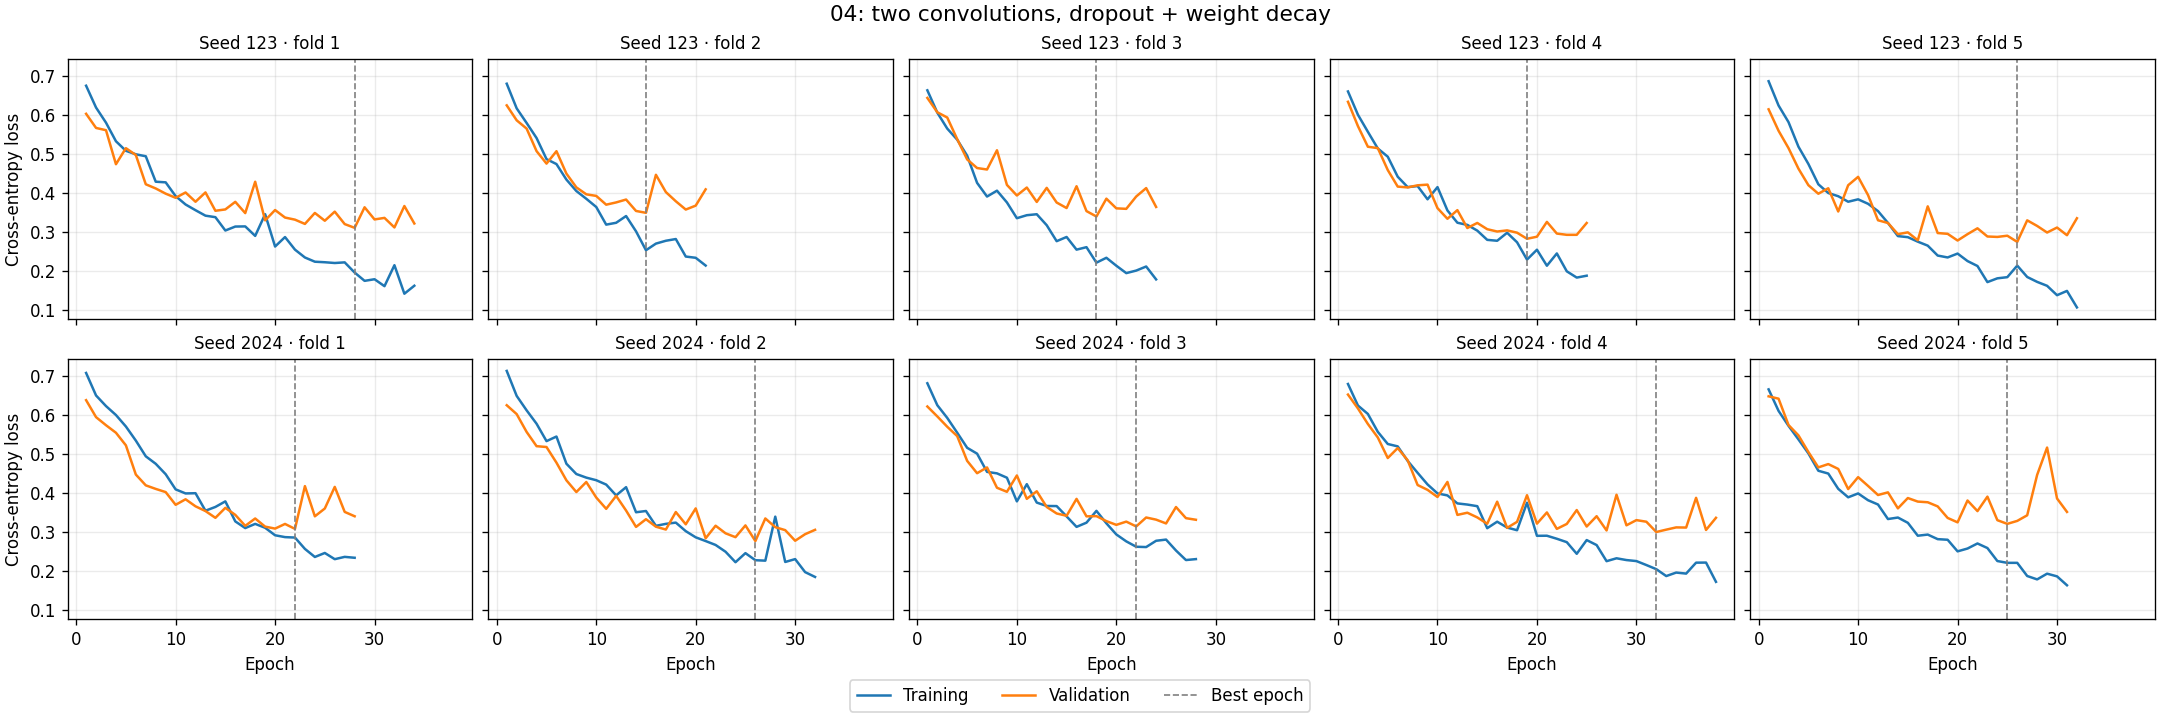

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6), sharex=True, sharey=True, constrained_layout=True)
for row, seed in enumerate((123, 2024)):
    for col in range(5):
        result = decay_curve_histories[(seed, col + 1)]
        epochs = range(1, len(result["train_losses"]) + 1)
        ax = axes[row, col]
        ax.plot(epochs, result["train_losses"], color="tab:blue", label="Training")
        ax.plot(epochs, result["val_losses"], color="tab:orange", label="Validation")
        ax.axvline(result["best_epoch"], color="gray", linestyle="--", linewidth=1, label="Best epoch")
        ax.set_title(f"Seed {seed} · fold {col+1}", fontsize=10)
        ax.grid(alpha=0.25)
        if row == 1: ax.set_xlabel("Epoch")
        if col == 0: ax.set_ylabel("Cross-entropy loss")
handles, labels = axes[0,0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3)
fig.suptitle("04: two convolutions, dropout + weight decay", fontsize=13)
plt.show()


### Observed GPU results

| Split seed | Mean fold log loss | Mean accuracy |
| --- | ---: | ---: |
| 123 | 0.3109 | 86.97% |
| 2024 | 0.3037 | 87.28% |

These are new results with weight decay 1e-4, separate from the earlier weight-decay-0 runs. Their per-epoch histories are saved above. Validation folds also select checkpoints, so results may be optimistic.
